# Flujo laminar sobre un escalón descendente (*backward-facing step*)
**Mecánica de Fluidos · Proyecto final**

Simulación numérica 2D del flujo incompresible y laminar que se separa en la arista de un escalón,
forma una burbuja de recirculación y se vuelve a adherir aguas abajo. El código es propio:
volúmenes finitos en malla escalonada (MAC), método de proyección de Chorin y presión por factorización LU.

| Bloque | Contenido |
|---|---|
| 0 | Librerías y parámetros de usuario (editar aquí para la demo en vivo) |
| 1 | Física: ecuaciones de gobierno, CI/CF y supuestos |
| 2 | Método numérico (malla MAC, proyección, estabilidad) |
| 3 | Código del solver |
| 4 | Caso base Re = 200 |
| 5 | Animación del transitorio |
| 6 | Análisis paramétrico: Re (viscosidad), malla, Δt, esquema convectivo |
| 7 | Validación contra la literatura |
| 8 | Conclusiones |

**Ejecutar todo** (*Kernel → Restart & Run All*) corre el notebook completo en unos 5–8 min en una laptop.
Sólo requiere `numpy`, `scipy` y `matplotlib`.

Referencia de partida: el notebook *Combined backward facing step* de kangluosee/CFD-Python (SIMPLE colocalizado
con interpolación de Rhie–Chow). Aquí se reescribió desde cero con otro método (proyección en malla escalonada),
vectorizado con NumPy, y se añadió el análisis paramétrico y la validación.

## 0. Librerías y parámetros de usuario

In [1]:
import time
import numpy as np
import scipy.sparse as sps
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML, display
from pathlib import Path

FIG = Path("figures"); FIG.mkdir(exist_ok=True)   # aquí se guardan las figuras del reporte
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})

In [2]:
# ===================== PARÁMETROS DE USUARIO (demo en vivo) =====================
RE_BASE  = 200     # número de Reynolds  Re = U H / nu   (equivale a variar la viscosidad)
NY_BASE  = 20      # celdas en la altura H del canal (malla uniforme dx = dy)
L_BASE   = 15.0    # longitud del dominio aguas abajo del escalón, en unidades de H
GAMMA    = 0.5     # esquema convectivo: 0 = centrado, 1 = upwind
DT_BASE  = None    # paso de tiempo; None = 50 % del límite de estabilidad
RUN_RE800 = True   # caso de validación Re = 800 (Gartling, 1990); tarda ~2-3 min
# =================================================================================

## 1. Física del problema

### Geometría
Canal de altura $H$ aguas abajo; el canal de entrada tiene altura $h = H - S$ y el escalón altura $S = H/2$
(relación de expansión $ER = H/h = 2$). La entrada se coloca justo en el plano del escalón ($x=0$), como en el
*benchmark* de Gartling (1990). El dominio es $0 \le x \le L$, $0 \le y \le H$.

### Ecuaciones de gobierno (adimensionales)
Con $U$ = velocidad media de entrada, $H$ como longitud y $\rho U^2$ como presión:

$$\nabla\cdot\mathbf{u} = 0, \qquad
\frac{\partial \mathbf{u}}{\partial t} + (\mathbf{u}\cdot\nabla)\mathbf{u} = -\nabla p + \frac{1}{Re}\nabla^2\mathbf{u},
\qquad Re = \frac{U H}{\nu}$$

$H = 2h$ es el diámetro hidráulico del canal de entrada, la definición que usan Armaly et al. (1983) y Gartling (1990).
**Variar la viscosidad $\nu$ equivale a variar $Re$.**

### Supuestos
Flujo 2D, incompresible ($\rho$ constante), newtoniano, isotérmico, laminar ($Re \le 800$), sin gravedad (no afecta la cinemática).

### Condiciones de frontera e inicial
| Frontera | Velocidad | Presión |
|---|---|---|
| Entrada $x=0,\ S<y<H$ | Poiseuille: $u = 6U\eta(1-\eta)$, $\eta = (y-S)/h$; $v=0$ | $\partial p/\partial n = 0$ |
| Cara del escalón $x=0,\ y<S$ | no deslizamiento $u=v=0$ | $\partial p/\partial n = 0$ |
| Paredes $y=0,\ y=H$ | no deslizamiento $u=v=0$ | $\partial p/\partial n = 0$ |
| Salida $x=L$ | $\partial u/\partial x = \partial v/\partial x = 0$ | $p = 0$ |

**CI:** fluido en reposo, $\mathbf{u}(x,y,0)=0$; se integra en el tiempo hasta el estado estacionario.

### El fenómeno
La capa límite no puede seguir la esquina convexa y se separa. Se forma una capa de corte libre que encierra
una **burbuja de recirculación** pegada a la pared inferior; la línea de corriente divisoria vuelve a la pared en
$x_r$ (**reacoplamiento**, donde $\tau_w = 0$). Al subir $Re$, $x_r$ crece casi linealmente, y para $Re \gtrsim 400$
el gradiente de presión adverso separa también la capa límite superior y aparece una **burbuja secundaria** en la pared de arriba.

## 2. Método numérico

**Malla escalonada (MAC):** $p$ en centros de celda, $u$ en caras verticales, $v$ en caras horizontales.
Así se evita el desacople presión–velocidad ("tablero de ajedrez") sin necesidad de Rhie–Chow.

**Proyección de Chorin (paso fraccionado)**, con $\mathbf{R} = \tfrac{1}{Re}\nabla^2\mathbf{u} - \nabla\cdot(\mathbf{u}\mathbf{u})$:
1. Predictor explícito: $\mathbf{u}^* = \mathbf{u}^n + \Delta t\,\mathbf{R}(\mathbf{u}^n)$
2. Poisson: $\nabla^2 p^{n+1} = \dfrac{\nabla\cdot\mathbf{u}^*}{\Delta t}$ (matriz de 5 puntos, factorizada **una vez** con LU dispersa)
3. Corrector: $\mathbf{u}^{n+1} = \mathbf{u}^* - \Delta t\,\nabla p^{n+1}$, que deja $\nabla\cdot\mathbf{u}^{n+1}=0$ a precisión de máquina.

**Discretización espacial:** difusión con diferencias centrales de 2.º orden; convección en forma conservativa
con el esquema híbrido de Hirt (Griebel et al., 1998):
$$\frac{\partial(u^2)}{\partial x}\Big|_i \approx \frac{u_e^2-u_w^2}{\Delta x} + \frac{\gamma}{\Delta x}\left[|u_e|\frac{u_i-u_{i+1}}{2} - |u_w|\frac{u_{i-1}-u_i}{2}\right],$$
con $\gamma=0$ (centrado, 2.º orden) y $\gamma=1$ (upwind, 1.er orden, más difusivo).

**Estabilidad (Euler explícito):**
$$\Delta t \le \min\left(\frac{\Delta x}{|u|_{max}},\ \frac{Re}{2}\Big(\frac{1}{\Delta x^2}+\frac{1}{\Delta y^2}\Big)^{-1}\right)$$
(CFL convectivo y número de Fourier difusivo). Por defecto se usa el 50 % de ese límite.

**Convergencia:** se detiene cuando $\max|\mathbf{u}^{n+1}-\mathbf{u}^n|/\Delta t < 10^{-5}$.

**Post-proceso:** $x_r$ es el cruce por cero (de $-$ a $+$) de $\tau_w \propto u$ en la primera celda junto a la pared.

## 3. Código del solver

### 3.1 Malla y operador de Poisson

In [3]:
# ---------------------------------------------------------------------------
# 1. Malla y operador de Poisson
# ---------------------------------------------------------------------------
def make_grid(L=20.0, H=1.0, S=0.5, ny=20):
    """Malla escalonada (MAC) uniforme dx = dy sobre [0,L] x [0,H]."""
    dy = H / ny
    nx = int(round(L / dy))
    dx = L / nx
    xc = (np.arange(nx) + 0.5) * dx          # centros de celda (p)
    yc = (np.arange(ny) + 0.5) * dy
    xf = np.arange(nx + 1) * dx              # caras x (u)
    yf = np.arange(ny + 1) * dy              # caras y (v)
    return dict(L=L, H=H, S=S, nx=nx, ny=ny, dx=dx, dy=dy,
                xc=xc, yc=yc, xf=xf, yf=yf)


def poisson_matrix(g):
    """Laplaciano de 5 puntos centrado en celda.
    Neumann (dp/dn = 0) en entrada y paredes; Dirichlet p = 0 en la salida."""
    nx, ny, dx, dy = g["nx"], g["ny"], g["dx"], g["dy"]

    def lap1d(n, h, dirichlet_right):
        main = -2.0 * np.ones(n)
        main[0] = -1.0                                   # Neumann izquierda/abajo
        main[-1] = -3.0 if dirichlet_right else -1.0     # p_ghost = -p (p_cara = 0)
        off = np.ones(n - 1)
        return sps.diags([off, main, off], [-1, 0, 1]) / h**2

    Dxx = lap1d(nx, dx, dirichlet_right=True)
    Dyy = lap1d(ny, dy, dirichlet_right=False)
    A = sps.kron(Dxx, sps.identity(ny)) + sps.kron(sps.identity(nx), Dyy)
    return spla.splu(A.tocsc())              # factorización LU (una sola vez)

### 3.2 Condiciones de frontera

In [4]:
# ---------------------------------------------------------------------------
# 2. Condiciones de frontera
# ---------------------------------------------------------------------------
def inlet_profile(g, Ub=1.0):
    """Perfil parabólico de Poiseuille en S < y < H con velocidad media Ub; 0 en la cara del escalón."""
    S, H, y = g["S"], g["H"], g["yc"]
    h = H - S
    eta = (y - S) / h
    u = np.where(y > S, 6.0 * Ub * eta * (1.0 - eta), 0.0)
    return u


def apply_bc(u, v, uin):
    """u: (nx+1, ny+2) con celdas fantasma en y;  v: (nx+2, ny+1) con fantasmas en x."""
    # entrada (x = 0): perfil impuesto / pared del escalón
    u[0, 1:-1] = uin
    v[0, :] = -v[1, :]                 # v = 0 en x = 0
    # salida (x = L): gradiente nulo
    u[-1, 1:-1] = u[-2, 1:-1]
    v[-1, :] = v[-2, :]
    # paredes inferior y superior: no deslizamiento
    u[:, 0] = -u[:, 1]
    u[:, -1] = -u[:, -2]
    v[:, 0] = 0.0
    v[:, -1] = 0.0

### 3.3 Términos de momento (convección + difusión)

In [5]:
# ---------------------------------------------------------------------------
# 3. Términos de momento (convección con esquema híbrido gamma + difusión central)
# ---------------------------------------------------------------------------
def momentum_rhs(u, v, nu, dx, dy, gamma):
    """Devuelve (Ru, Rv) = nu*lap(u) - conv(u) en caras interiores."""
    # ---- ecuación x, nodos u[1:-1, 1:-1] ----
    uc = u[1:-1, 1:-1]
    uE, uW = u[2:, 1:-1], u[:-2, 1:-1]
    uN, uS = u[1:-1, 2:], u[1:-1, :-2]
    lap_u = (uE - 2 * uc + uW) / dx**2 + (uN - 2 * uc + uS) / dy**2

    ue, uw = 0.5 * (uc + uE), 0.5 * (uW + uc)            # velocidades en caras
    du2dx = (ue**2 - uw**2 + gamma * (np.abs(ue) * (uc - uE) / 2
                                      - np.abs(uw) * (uW - uc) / 2)) / dx
    vn = 0.5 * (v[1:-2, 1:] + v[2:-1, 1:])               # v promedio arriba de u
    vs = 0.5 * (v[1:-2, :-1] + v[2:-1, :-1])             # v promedio abajo de u
    duvdy = (vn * 0.5 * (uc + uN) - vs * 0.5 * (uS + uc)
             + gamma * (np.abs(vn) * (uc - uN) / 2 - np.abs(vs) * (uS - uc) / 2)) / dy
    Ru = nu * lap_u - du2dx - duvdy

    # ---- ecuación y, nodos v[1:-1, 1:-1] ----
    vc = v[1:-1, 1:-1]
    vE, vW = v[2:, 1:-1], v[:-2, 1:-1]
    vN, vS = v[1:-1, 2:], v[1:-1, :-2]
    lap_v = (vE - 2 * vc + vW) / dx**2 + (vN - 2 * vc + vS) / dy**2

    vnn, vss = 0.5 * (vc + vN), 0.5 * (vS + vc)
    dv2dy = (vnn**2 - vss**2 + gamma * (np.abs(vnn) * (vc - vN) / 2
                                         - np.abs(vss) * (vS - vc) / 2)) / dy
    ue_ = 0.5 * (u[1:, 1:-2] + u[1:, 2:-1])              # u promedio a la derecha de v
    uw_ = 0.5 * (u[:-1, 1:-2] + u[:-1, 2:-1])            # u promedio a la izquierda de v
    duvdx = (ue_ * 0.5 * (vc + vE) - uw_ * 0.5 * (vW + vc)
             + gamma * (np.abs(ue_) * (vc - vE) / 2 - np.abs(uw_) * (vW - vc) / 2)) / dx
    Rv = nu * lap_v - duvdx - dv2dy
    return Ru, Rv

### 3.4 Paso fraccionado e integración en el tiempo

In [6]:
# ---------------------------------------------------------------------------
# 4. Paso fraccionado (proyección de Chorin) e integración en el tiempo
# ---------------------------------------------------------------------------
def stable_dt(g, Re, Umax=1.5, safety=0.5):
    """Límite explícito: CFL convectivo y número de Fourier difusivo."""
    dx, dy = g["dx"], g["dy"]
    dt_conv = min(dx, dy) / Umax
    dt_diff = 0.5 * Re / (1 / dx**2 + 1 / dy**2)
    return safety * min(dt_conv, dt_diff), dt_conv, dt_diff


def solve_bfs(Re=200, ny=20, L=20.0, S=0.5, dt=None, gamma=0.5, t_end=200.0,
              tol=1e-5, snap_every=None, verbose=True, max_div=1e3):
    """Integra Navier–Stokes 2D hasta estado estacionario (o t_end).

    Re  : número de Reynolds basado en la velocidad media de entrada Ub = 1 y en
          la altura del canal aguas abajo H = 1 (diámetro hidráulico de entrada).
    ny  : celdas en la altura H (malla uniforme dx = dy).
    dt  : paso de tiempo; None -> 50 % del límite de estabilidad.
    gamma : 0 = diferencias centrales, 1 = upwind puro (donor cell).
    """
    g = make_grid(L=L, H=1.0, S=S, ny=ny)
    nx, dx, dy = g["nx"], g["dx"], g["dy"]
    nu = 1.0 / Re
    if dt is None:
        dt = stable_dt(g, Re)[0]

    lu = poisson_matrix(g)
    uin = inlet_profile(g)

    u = np.zeros((nx + 1, ny + 2))
    v = np.zeros((nx + 2, ny + 1))
    u[:, 1:-1] = uin[None, :] * 0.0     # condición inicial: fluido en reposo
    apply_bc(u, v, uin)
    p = np.zeros((nx, ny))

    hist_t, hist_res, snaps = [], [], []
    n_steps = int(round(t_end / dt))
    status = "max_time"
    t0 = time.time()
    for n in range(1, n_steps + 1):
        Ru, Rv = momentum_rhs(u, v, nu, dx, dy, gamma)

        # (a) velocidad intermedia u*
        F = u[:, 1:-1].copy()
        G = v[1:-1, :].copy()
        F[1:-1, :] += dt * Ru
        G[:, 1:-1] += dt * Rv
        F[-1, :] = F[-2, :]               # estimación en la salida

        # (b) Poisson para la presión:  lap(p) = div(u*) / dt
        div = (F[1:, :] - F[:-1, :]) / dx + (G[:, 1:] - G[:, :-1]) / dy
        p = lu.solve((div / dt).ravel()).reshape(nx, ny)

        # (c) corrección: u^{n+1} = u* - dt grad(p)
        u_old = u[:, 1:-1].copy()
        u[1:-1, 1:-1] = F[1:-1, :] - dt * (p[1:, :] - p[:-1, :]) / dx
        u[-1, 1:-1] = F[-1, :] - dt * (-2.0 * p[-1, :]) / dx   # p = 0 en la salida
        v[1:-1, 1:-1] = G[:, 1:-1] - dt * (p[:, 1:] - p[:, :-1]) / dy
        # sólo fantasmas; u en la salida se conserva para garantizar masa
        u[0, 1:-1] = uin
        v[0, :] = -v[1, :]
        v[-1, :] = v[-2, :]
        u[:, 0] = -u[:, 1]
        u[:, -1] = -u[:, -2]

        res = np.max(np.abs(u[:, 1:-1] - u_old)) / dt
        if n % 10 == 0 or n == 1:
            hist_t.append(n * dt)
            hist_res.append(res)
        if snap_every and n % snap_every == 0:
            snaps.append((n * dt, u.copy(), v.copy()))
        if not np.isfinite(res) or res > max_div:
            status = "diverged"
            if verbose:
                print(f"  ¡Divergencia en t = {n*dt:.3f}! (residuo = {res:.2e})")
            break
        if res < tol and n * dt > 5.0:
            status = "converged"
            break

    t_cpu = time.time() - t0
    out = dict(g=g, Re=Re, nu=nu, dt=dt, gamma=gamma, u=u, v=v, p=p, t=n * dt,
               steps=n, status=status, cpu=t_cpu, uin=uin,
               hist_t=np.array(hist_t), hist_res=np.array(hist_res), snaps=snaps)
    if status != "diverged":
        out.update(reattachment(out))
    if verbose:
        msg = f"Re={Re:4d} ny={ny:3d} dt={dt:.4f} gamma={gamma:.2f} -> {status} " \
              f"t={n*dt:7.2f} ({n} pasos, {t_cpu:5.1f} s)"
        if status != "diverged":
            msg += f"  x_r/S = {out['xr']/S:5.2f}"
        print(msg)
    return out

### 3.5 Post-proceso: reacoplamiento, vorticidad, función de corriente

In [7]:
# ---------------------------------------------------------------------------
# 5. Post-proceso
# ---------------------------------------------------------------------------
def _crossings(x, f, direction):
    """Posiciones donde f cruza cero; direction=+1 (de - a +) o -1 (de + a -)."""
    idx = np.where((np.sign(f[:-1]) == -direction) & (np.sign(f[1:]) == direction))[0]
    return np.array([x[i] - f[i] * (x[i + 1] - x[i]) / (f[i + 1] - f[i]) for i in idx])


def reattachment(res):
    """Longitudes de recirculación a partir del signo del esfuerzo cortante en paredes.

    x_r : reacoplamiento de la burbuja principal (pared inferior, tau_w de - a +),
          tomado aguas abajo del mínimo de u (así se ignora el pequeño vórtice de esquina).
    x_s, x_e : separación y reacoplamiento de la burbuja secundaria (pared superior).
    """
    g, u = res["g"], res["u"]
    xf = g["xf"]
    u_bot = u[:, 1]             # primera fila sobre la pared inferior (tau_w ~ u / (dy/2))
    u_top = u[:, -2]            # primera fila bajo la pared superior
    i_min = int(np.argmin(u_bot))
    up = _crossings(xf, u_bot, +1)
    up = up[up > xf[i_min]]
    xr = up[0] if up.size else np.nan
    sep = _crossings(xf, u_top, -1)
    xs = sep[0] if sep.size else np.nan
    att = _crossings(xf, u_top, +1)
    att = att[att > xs] if sep.size else att[:0]
    xe = att[0] if att.size else np.nan
    return dict(xr=xr, xs=xs, xe=xe)


def cell_fields(res):
    """Interpola u, v a centros de celda; calcula |V|, vorticidad y función de corriente."""
    g, u, v = res["g"], res["u"], res["v"]
    dx, dy = g["dx"], g["dy"]
    uc = 0.5 * (u[1:, 1:-1] + u[:-1, 1:-1])
    vc = 0.5 * (v[1:-1, 1:] + v[1:-1, :-1])
    speed = np.hypot(uc, vc)
    # vorticidad en nodos (esquinas de celda): w = dv/dx - du/dy
    w = (v[1:, :] - v[:-1, :]) / dx - (u[:, 1:] - u[:, :-1]) / dy
    # función de corriente en esquinas: psi(x, y) = int_0^y u dy
    psi = np.zeros((g["nx"] + 1, g["ny"] + 1))
    psi[:, 1:] = np.cumsum(u[:, 1:-1], axis=1) * dy
    return dict(uc=uc, vc=vc, speed=speed, w=w, psi=psi)


def divergence_norm(res):
    g, u, v = res["g"], res["u"], res["v"]
    div = (u[1:, 1:-1] - u[:-1, 1:-1]) / g["dx"] + (v[1:-1, 1:] - v[1:-1, :-1]) / g["dy"]
    return np.max(np.abs(div))

### 3.6 Funciones de graficado

In [8]:
S_COLOR = "0.35"
def _step(ax, res):
    """Dibuja el escalón (la entrada está en x = 0, el escalón ocupa 0 < y < S)."""
    S = res["g"]["S"]
    ax.add_patch(patches.Rectangle((-0.6, 0), 0.6, S, fc=S_COLOR, ec="k", hatch="///"))
    ax.set_xlim(-0.6, None)


def plot_fields(res, xmax=None, fname=None):
    """|V| con líneas de corriente, vorticidad y presión."""
    g = res["g"]
    f = cell_fields(res)
    xmax = xmax or g["L"]
    S = g["S"]
    X, Y = np.meshgrid(g["xc"], g["yc"], indexing="ij")
    Xf, Yf = np.meshgrid(g["xf"], g["yf"], indexing="ij")

    fig, axs = plt.subplots(3, 1, figsize=(12, 6.2), sharex=True, constrained_layout=True)
    cs = axs[0].contourf(X, Y, f["speed"], levels=40, cmap="viridis")
    axs[0].contour(Xf, Yf, f["psi"], levels=np.r_[np.linspace(-0.03, -0.001, 6), np.linspace(0.02, 0.98, 12)],
                   colors="w", linewidths=0.6)
    fig.colorbar(cs, ax=axs[0], label="|V| / U")
    axs[0].set_title(f"Re = {res['Re']}: magnitud de velocidad y líneas de corriente   "
                     f"(x_r/S = {res['xr']/S:.2f})")

    wmax = np.percentile(np.abs(f["w"]), 98)
    cs = axs[1].contourf(Xf, Yf, f["w"], levels=np.linspace(-wmax, wmax, 41), cmap="RdBu_r", extend="both")
    fig.colorbar(cs, ax=axs[1], label="ω H / U")
    axs[1].set_title("Vorticidad")

    cs = axs[2].contourf(X, Y, res["p"], levels=40, cmap="coolwarm")
    fig.colorbar(cs, ax=axs[2], label="p / ρU²")
    axs[2].set_title("Presión")

    for ax in axs:
        _step(ax, res)
        ax.axvline(res["xr"], color="r", ls="--", lw=1)
        ax.set_xlim(-0.6, xmax)
        ax.set_aspect("equal")
        ax.set_ylabel("y / H")
    axs[-1].set_xlabel("x / H")
    if fname:
        fig.savefig(fname, dpi=150)
    return fig


def plot_profiles(res, stations=(0.0, 1.0, 2.0, 3.0, 4.0, 6.0, 8.0), fname=None):
    """Perfiles u(y) en varias estaciones x (escalados y desplazados)."""
    g = res["g"]
    u = res["u"][:, 1:-1]
    fig, ax = plt.subplots(figsize=(12, 2.8), constrained_layout=True)
    for xs in stations:
        i = int(round(xs / g["dx"]))
        ax.plot(xs + 0.8 * u[i], g["yc"], "b-")
        ax.axvline(xs, color="0.6", lw=0.6)
    _step(ax, res)
    ax.axvline(res["xr"], color="r", ls="--", lw=1, label="reacoplamiento")
    ax.set_xlim(-0.6, max(stations) + 1.5)
    ax.set_xlabel("x / H  (perfil: x + 0.8 u/U)")
    ax.set_ylabel("y / H")
    ax.set_title(f"Perfiles de velocidad u(y), Re = {res['Re']}")
    ax.legend(loc="upper right")
    if fname:
        fig.savefig(fname, dpi=150)
    return fig


def plot_wall_shear(results, fname=None):
    """u en la primera celda junto a la pared inferior (proporcional a τ_w)."""
    fig, ax = plt.subplots(figsize=(9, 3.2), constrained_layout=True)
    for r in results:
        g = r["g"]
        tau = r["nu"] * r["u"][:, 1] / (0.5 * g["dy"])
        ax.plot(g["xf"] / g["S"], tau, label=f"Re = {r['Re']}")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlim(0, 25)
    ax.set_xlabel("x / S")
    ax.set_ylabel("τ_w / ρU²  (pared inferior)")
    ax.set_title("Esfuerzo cortante en la pared inferior: τ_w = 0 marca el reacoplamiento")
    ax.legend()
    if fname:
        fig.savefig(fname, dpi=150)
    return fig


def plot_convergence(results, labels, fname=None):
    fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
    for r, lab in zip(results, labels):
        ax.semilogy(r["hist_t"], r["hist_res"], label=lab)
    ax.set_xlabel("t U / H")
    ax.set_ylabel("max |Δu| / Δt")
    ax.set_title("Historia de convergencia hacia el estado estacionario")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
    if fname:
        fig.savefig(fname, dpi=150)
    return fig

## 4. Caso base
Se resuelve con los parámetros del bloque 0 (por defecto Re = 200, 20 celdas por H). Se verifica que la divergencia
discreta sea ~0 y se grafican los campos.

In [9]:
base = solve_bfs(Re=RE_BASE, ny=NY_BASE, L=L_BASE, dt=DT_BASE, gamma=GAMMA, snap_every=15)
print(f"max |div u| = {divergence_norm(base):.1e}   (incompresibilidad a precisión de máquina)")
S = base["g"]["S"]
print(f"Reacoplamiento x_r = {base['xr']:.3f} H  ->  x_r/S = {base['xr']/S:.2f}")

Re= 200 ny= 20 dt=0.0167 gamma=0.50 -> converged t=  48.60 (2916 pasos,   4.0 s)  x_r/S =  4.90
max |div u| = 5.0e-15   (incompresibilidad a precisión de máquina)
Reacoplamiento x_r = 2.450 H  ->  x_r/S = 4.90


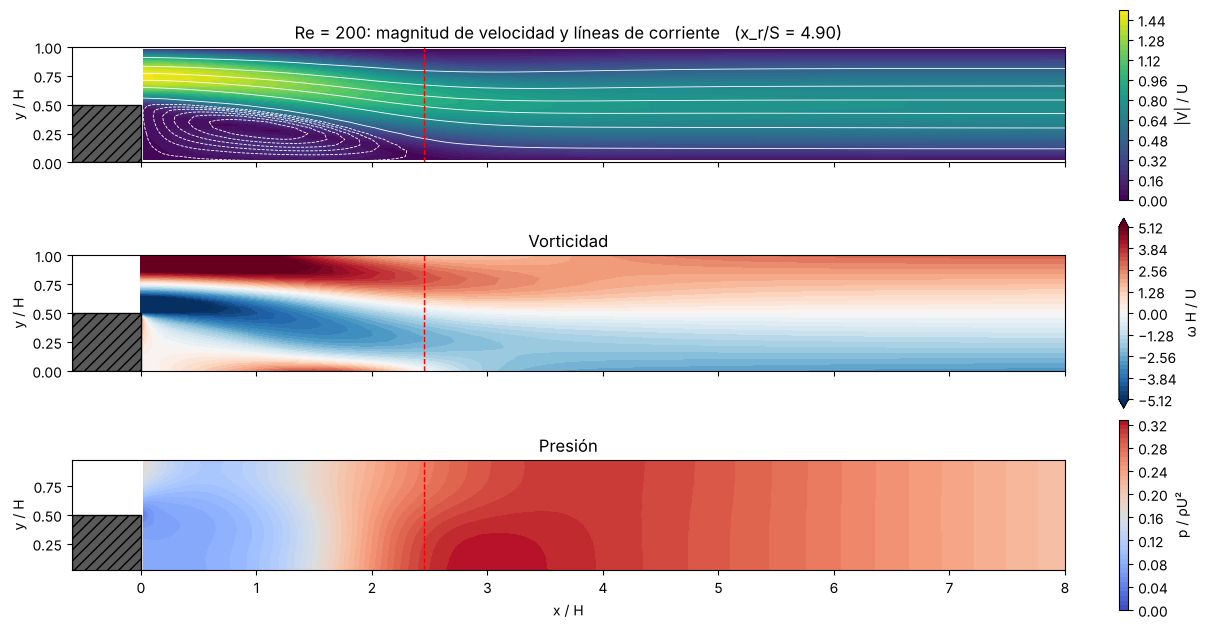

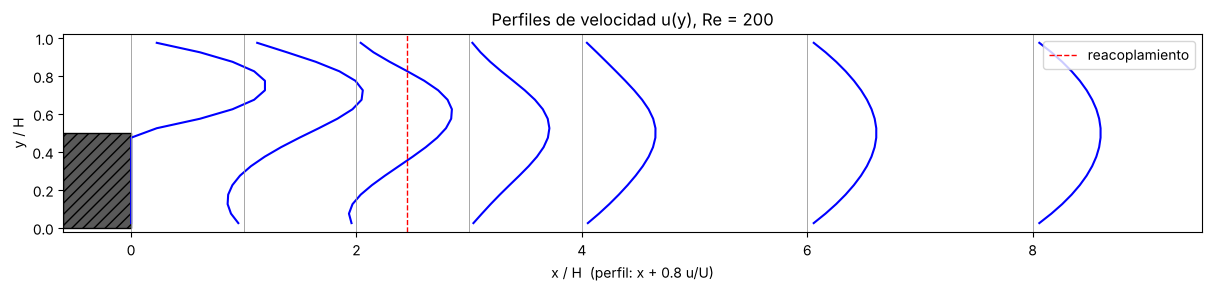

In [10]:
plot_fields(base, xmax=8, fname=FIG / "campos_base.png"); plt.show()
plot_profiles(base, fname=FIG / "perfiles_base.png"); plt.show()

**Lectura física.** Aguas abajo de la esquina el perfil parabólico se "despega" de la pared: aparece una zona con
$u<0$ (recirculación, vorticidad negativa intensa en la capa de corte). En $x_r$ el flujo se vuelve a adherir y el
perfil evoluciona de nuevo hacia una parábola que ocupa todo el canal ($u_{max} = 1.5 \to 0.75$ por conservación de masa).
La presión **sube** a lo largo del canal en la zona de expansión (recuperación de presión, gradiente adverso).

## 5. Animación del transitorio (arranque desde el reposo)

In [11]:
def animate_run(res, xmax=8, every=1, fname=None):
    g = res["g"]; snaps = res["snaps"][::every]
    X, Y = np.meshgrid(g["xc"], g["yc"], indexing="ij")
    fig, ax = plt.subplots(figsize=(10, 2.3), constrained_layout=True)

    def frame(k):
        t, u, v = snaps[k]
        ax.clear()
        uc = 0.5 * (u[1:, 1:-1] + u[:-1, 1:-1]); vc = 0.5 * (v[1:-1, 1:] + v[1:-1, :-1])
        ax.contourf(X, Y, np.hypot(uc, vc), levels=np.linspace(0, 1.6, 33), cmap="viridis")
        ax.streamplot(g["xc"], g["yc"], uc.T, vc.T, color="w", density=1.2, linewidth=0.5, arrowsize=0.6)
        ax.add_patch(patches.Rectangle((-0.6, 0), 0.6, g["S"], fc="0.35", ec="k", hatch="///"))
        ax.set_xlim(-0.6, xmax); ax.set_ylim(0, 1); ax.set_aspect("equal")
        ax.set_title(f"Re = {res['Re']}   t U/H = {t:5.1f}")
        return []

    ani = FuncAnimation(fig, frame, frames=len(snaps), interval=120)
    if fname:
        ani.save(fname, writer=PillowWriter(fps=8))
    plt.close(fig)
    return ani

ani = animate_run(base, every=max(1, len(base["snaps"]) // 60), fname=FIG / "transitorio.gif")
display(HTML(ani.to_jshtml()))

## 6. Análisis paramétrico
### 6.1 Efecto del número de Reynolds (viscosidad)
$Re = UH/\nu$: bajar la viscosidad equivale a subir $Re$. Se usa un dominio más largo ($L = 25H$) para que la burbuja
secundaria y el reacoplamiento no toquen la salida.

In [12]:
RE_LIST = [100, 200, 300, 400, 600]
runs_re = [solve_bfs(Re=Re, ny=20, L=25.0, gamma=GAMMA, t_end=500) for Re in RE_LIST]

print("\n  Re    nu       x_r/S   x_s/S   x_e/S  (burbuja secundaria, pared superior)")
for r in runs_re:
    print(f"{r['Re']:5d}  {r['nu']:.5f}  {r['xr']/S:6.2f}  {r['xs']/S:6.2f}  {r['xe']/S:6.2f}")

Re= 100 ny= 20 dt=0.0167 gamma=0.50 -> converged t=  23.93 (1436 pasos,   3.4 s)  x_r/S =  3.01


Re= 200 ny= 20 dt=0.0167 gamma=0.50 -> converged t=  48.60 (2916 pasos,   6.9 s)  x_r/S =  4.90


Re= 300 ny= 20 dt=0.0167 gamma=0.50 -> converged t=  83.65 (5019 pasos,  10.1 s)  x_r/S =  6.52


Re= 400 ny= 20 dt=0.0167 gamma=0.50 -> converged t= 139.60 (8376 pasos,  17.5 s)  x_r/S =  7.90


Re= 600 ny= 20 dt=0.0167 gamma=0.50 -> converged t= 316.22 (18973 pasos,  38.3 s)  x_r/S =  9.75

  Re    nu       x_r/S   x_s/S   x_e/S  (burbuja secundaria, pared superior)
  100  0.01000    3.01     nan     nan
  200  0.00500    4.90     nan     nan
  300  0.00333    6.52     nan     nan
  400  0.00250    7.90    7.89    8.14
  600  0.00167    9.75    7.99   13.45


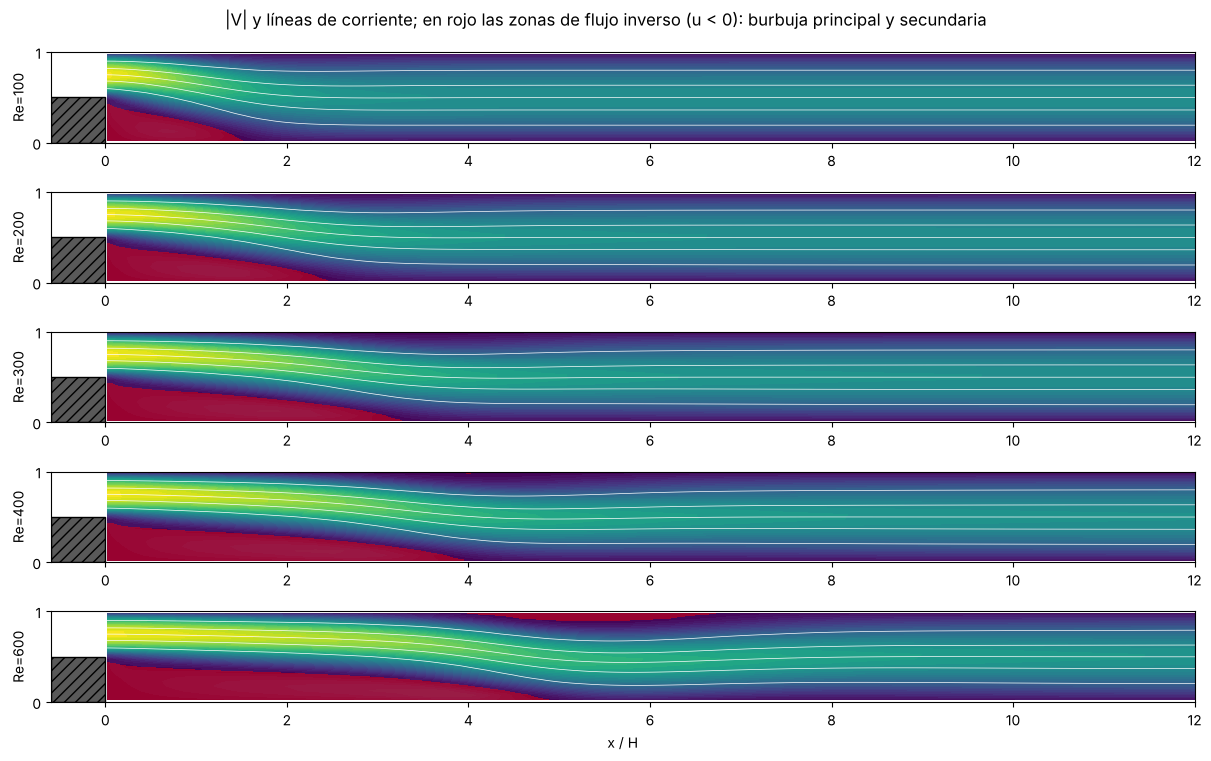

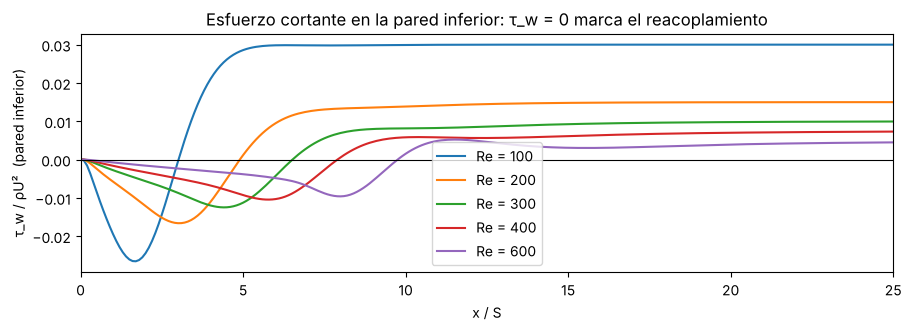

In [13]:
fig = plt.figure(figsize=(12, 7.5), constrained_layout=True)
gs = fig.add_gridspec(len(runs_re), 1)
for k, r in enumerate(runs_re):
    ax = fig.add_subplot(gs[k]); g = r["g"]; f = cell_fields(r)
    Xf, Yf = np.meshgrid(g["xf"], g["yf"], indexing="ij")
    X, Y = np.meshgrid(g["xc"], g["yc"], indexing="ij")
    ax.contourf(X, Y, f["speed"], levels=40, cmap="viridis")
    ax.contourf(X, Y, f["uc"], levels=[-10, 0], colors="red", alpha=0.45)      # zonas con u < 0
    ax.contour(Xf, Yf, f["psi"], levels=np.linspace(0.05, 0.95, 10), colors="w", linewidths=0.5)
    ax.add_patch(patches.Rectangle((-0.6, 0), 0.6, S, fc="0.35", ec="k", hatch="///"))
    ax.set_xlim(-0.6, 12); ax.set_aspect("equal"); ax.set_yticks([0, 1])
    ax.set_ylabel(f"Re={r['Re']}")
ax.set_xlabel("x / H")
fig.suptitle("|V| y líneas de corriente; en rojo las zonas de flujo inverso (u < 0): burbuja principal y secundaria")
fig.savefig(FIG / "re_streamfunction.png", dpi=150); plt.show()

plot_wall_shear(runs_re, fname=FIG / "re_tau_w.png"); plt.show()

### 6.2 Independencia de malla
Caso Re = 200 con 10, 20 y 40 celdas por $H$ (refinamiento $r = 2$). Con la extrapolación de Richardson se estima
el orden observado $p$ y el valor "exacto" de $x_r$, y con eso el índice de convergencia de malla (GCI, Roache).

Re= 200 ny= 10 dt=0.0333 gamma=0.50 -> converged t=  45.13 (1354 pasos,   0.5 s)  x_r/S =  4.47


Re= 200 ny= 20 dt=0.0167 gamma=0.50 -> converged t=  48.60 (2916 pasos,   3.6 s)  x_r/S =  4.90


Re= 200 ny= 40 dt=0.0083 gamma=0.50 -> converged t=  51.02 (6123 pasos,  32.4 s)  x_r/S =  5.11
ny =  10  celdas =   1500  x_r/S = 4.466  CPU =   0.5 s
ny =  20  celdas =   6000  x_r/S = 4.899  CPU =   3.6 s
ny =  40  celdas =  24000  x_r/S = 5.114  CPU =  32.4 s
Orden observado p = 1.02;  Richardson x_r/S = 5.323;  GCI(malla fina) = 5.13 %


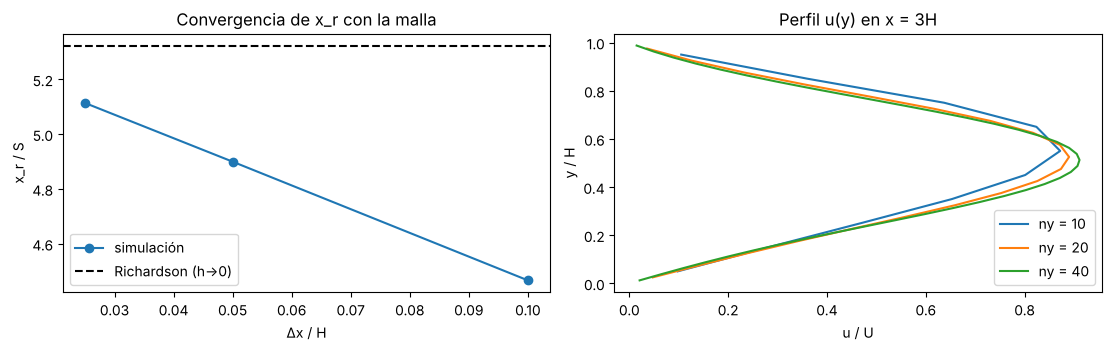

In [14]:
NY_LIST = [10, 20, 40]
runs_mesh = [solve_bfs(Re=200, ny=ny, L=15.0, gamma=GAMMA) for ny in NY_LIST]
xr = np.array([r["xr"] / S for r in runs_mesh])
p_obs = np.log(abs(xr[1] - xr[0]) / abs(xr[2] - xr[1])) / np.log(2)
xr_ext = xr[2] + (xr[2] - xr[1]) / (2**p_obs - 1)
gci = 1.25 * abs((xr[2] - xr[1]) / xr[2]) / (2**p_obs - 1) * 100
for ny, x, r in zip(NY_LIST, xr, runs_mesh):
    print(f"ny = {ny:3d}  celdas = {r['g']['nx']*ny:6d}  x_r/S = {x:.3f}  CPU = {r['cpu']:5.1f} s")
print(f"Orden observado p = {p_obs:.2f};  Richardson x_r/S = {xr_ext:.3f};  GCI(malla fina) = {gci:.2f} %")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), constrained_layout=True)
h = 1 / np.array(NY_LIST)
ax[0].plot(h, xr, "o-", label="simulación"); ax[0].axhline(xr_ext, color="k", ls="--", label="Richardson (h→0)")
ax[0].set_xlabel("Δx / H"); ax[0].set_ylabel("x_r / S"); ax[0].set_title("Convergencia de x_r con la malla"); ax[0].legend()
for r, ny in zip(runs_mesh, NY_LIST):
    i = int(round(3.0 / r["g"]["dx"]))
    ax[1].plot(r["u"][i, 1:-1], r["g"]["yc"], label=f"ny = {ny}")
ax[1].set_xlabel("u / U"); ax[1].set_ylabel("y / H"); ax[1].set_title("Perfil u(y) en x = 3H"); ax[1].legend()
fig.savefig(FIG / "malla.png", dpi=150); plt.show()

### 6.3 Paso de tiempo y estabilidad
Re = 200, ny = 20. El límite convectivo es $\Delta t_{CFL} = \Delta x/u_{max} = 0.033$ y el difusivo
$\Delta t_{Fo} = 0.125$; manda el convectivo. Se prueban valores por debajo y por encima.

dt_CFL = 0.0333   dt_Fourier = 0.1250   dt por defecto = 0.0167


Re= 200 ny= 20 dt=0.0050 gamma=0.50 -> converged t=  48.61 (9721 pasos,  12.7 s)  x_r/S =  4.90


Re= 200 ny= 20 dt=0.0167 gamma=0.50 -> converged t=  48.60 (2910 pasos,   3.6 s)  x_r/S =  4.90


Re= 200 ny= 20 dt=0.0300 gamma=0.50 -> converged t=  48.60 (1620 pasos,   2.2 s)  x_r/S =  4.90


Re= 200 ny= 20 dt=0.0360 gamma=0.50 -> converged t=  48.60 (1350 pasos,   1.6 s)  x_r/S =  4.90
  ¡Divergencia en t = 0.990! (residuo = 1.92e+03)
Re= 200 ny= 20 dt=0.0450 gamma=0.50 -> diverged t=   0.99 (22 pasos,   0.0 s)


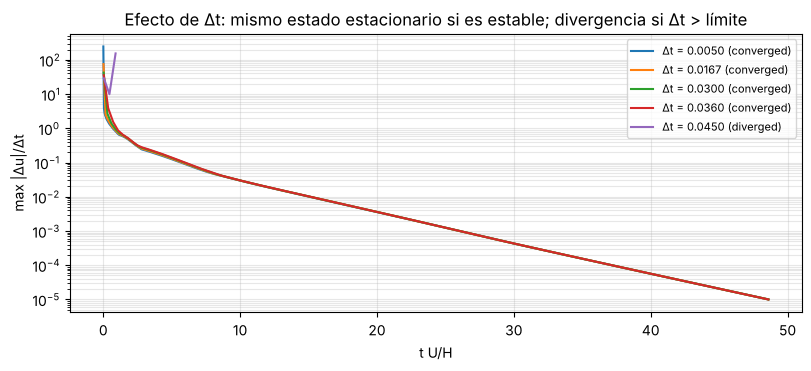

dt = 0.0050  (0.15 dt_CFL)  converged  pasos =  9721  x_r/S = 4.899
dt = 0.0167  (0.50 dt_CFL)  converged  pasos =  2910  x_r/S = 4.899
dt = 0.0300  (0.90 dt_CFL)  converged  pasos =  1620  x_r/S = 4.899
dt = 0.0360  (1.08 dt_CFL)  converged  pasos =  1350  x_r/S = 4.899
dt = 0.0450  (1.35 dt_CFL)  diverged   pasos =    22  x_r/S = —


In [15]:
g20 = make_grid(L=15.0, ny=20)
dt_safe, dt_cfl, dt_fo = stable_dt(g20, 200)
print(f"dt_CFL = {dt_cfl:.4f}   dt_Fourier = {dt_fo:.4f}   dt por defecto = {dt_safe:.4f}")
DT_LIST = [0.005, 0.0167, 0.030, 0.036, 0.045]
runs_dt = [solve_bfs(Re=200, ny=20, L=15.0, dt=dt, gamma=GAMMA, t_end=150) for dt in DT_LIST]

fig, ax = plt.subplots(figsize=(8, 3.6), constrained_layout=True)
for r in runs_dt:
    ax.semilogy(r["hist_t"], r["hist_res"], label=f"Δt = {r['dt']:.4f} ({r['status']})")
ax.set_xlabel("t U/H"); ax.set_ylabel("max |Δu|/Δt"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
ax.set_title("Efecto de Δt: mismo estado estacionario si es estable; divergencia si Δt > límite")
fig.savefig(FIG / "dt.png", dpi=150); plt.show()
for r in runs_dt:
    xr_txt = f"{r['xr']/S:.3f}" if r["status"] != "diverged" else "—"
    print(f"dt = {r['dt']:.4f}  ({r['dt']/dt_cfl:4.2f} dt_CFL)  {r['status']:9s}  pasos = {r['steps']:5d}  x_r/S = {xr_txt}")

Mientras el esquema es estable, el estado estacionario **no depende** de $\Delta t$ (mismo $x_r$); un $\Delta t$ mayor
sólo llega antes. Por encima de ~1.1 $\Delta t_{CFL}$ los errores crecen exponencialmente y la solución diverge en pocas
iteraciones. El término $\gamma$-upwind añade algo de disipación, por eso el límite real queda un poco por encima del CFL teórico.

### 6.4 Esquema convectivo (difusión numérica)
Re = 200, ny = 20: comparación de $\gamma = 0$ (centrado), $0.5$ y $1$ (upwind). El esquema centrado con Euler explícito
tiene una restricción extra, $\Delta t \le 2\nu/|u|^2_{max}$ (Griebel et al.): a Re = 200 eso es $\Delta t \le 0.0044$,
así que para $\gamma = 0$ se usa $\Delta t = 0.004$ (con el $\Delta t$ por defecto diverge).

Re= 200 ny= 20 dt=0.0040 gamma=0.00 -> converged t=  54.27 (13568 pasos,  16.9 s)  x_r/S =  5.33


Re= 200 ny= 20 dt=0.0167 gamma=0.50 -> converged t=  48.60 (2916 pasos,   4.1 s)  x_r/S =  4.90


Re= 200 ny= 20 dt=0.0167 gamma=1.00 -> converged t=  44.48 (2669 pasos,   3.8 s)  x_r/S =  4.50
gamma = 0.0  x_r/S = 5.33
gamma = 0.5  x_r/S = 4.90
gamma = 1.0  x_r/S = 4.50


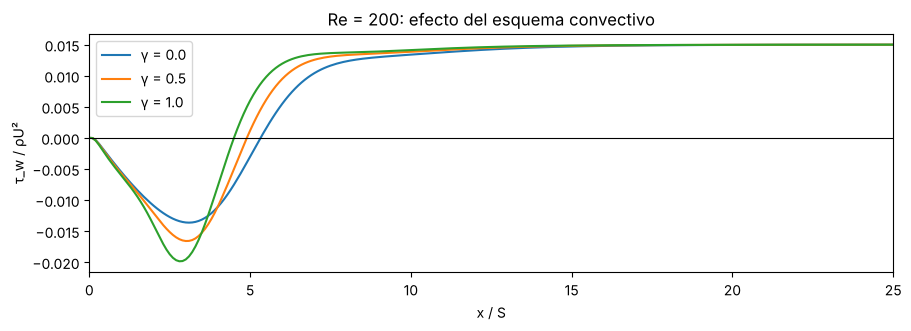

In [16]:
runs_gamma = [solve_bfs(Re=200, ny=20, L=15.0, gamma=0.0, dt=0.004),
              solve_bfs(Re=200, ny=20, L=15.0, gamma=0.5),
              solve_bfs(Re=200, ny=20, L=15.0, gamma=1.0)]
for r in runs_gamma:
    print(f"gamma = {r['gamma']:.1f}  x_r/S = {r['xr']/S:.2f}")
fig, ax = plt.subplots(figsize=(9, 3.2), constrained_layout=True)
for r in runs_gamma:
    ax.plot(r["g"]["xf"] / S, r["nu"] * r["u"][:, 1] / (0.5 * r["g"]["dy"]), label=f"γ = {r['gamma']}")
ax.axhline(0, color="k", lw=0.8); ax.set_xlim(0, 25); ax.legend()
ax.set_xlabel("x / S"); ax.set_ylabel("τ_w / ρU²"); ax.set_title("Re = 200: efecto del esquema convectivo")
fig.savefig(FIG / "gamma.png", dpi=150); plt.show()

El upwind puro ($\gamma=1$) introduce una viscosidad numérica $\nu_{num}\approx \gamma|u|\Delta x/2$. Con
$\Delta x = 0.05$ y $|u|\sim 1$ da $\nu_{num}\approx 0.025$, **cinco veces** la viscosidad física a Re = 200
($\nu = 0.005$): el flujo se comporta como si tuviera un $Re$ efectivo menor y la burbuja se acorta.
El centrado es el más preciso pero exige un $\Delta t$ ~4 veces menor (y a Re = 400 con el $\Delta t$ por defecto diverge en
menos de 100 pasos). El valor intermedio $\gamma=0.5$ es el compromiso que se usa en el resto del trabajo, y es la causa principal
de que el orden observado de convergencia en malla sea ~1.

## 7. Validación contra la literatura
Se compara $x_r/S$ con datos numéricos 2D de referencia (tabla de Re = 100–800 recopilada en arXiv:2507.16509) y con el
*benchmark* clásico de Gartling (1990) en Re = 800 ($x_r = 6.10H$ → $x_r/S = 12.2$; burbuja superior de $4.85H$ a $10.48H$).
Los experimentos de Armaly et al. (1983) coinciden con las simulaciones 2D sólo hasta Re ≈ 400; arriba el flujo real se vuelve 3D.

Re= 800 ny= 20 dt=0.0167 gamma=0.50 -> converged t= 324.45 (19467 pasos,  44.3 s)  x_r/S = 10.45
Re = 800: x_r/S = 10.45 (Gartling 12.2);  burbuja superior 4.18H – 8.07H (Gartling 4.85H – 10.48H)


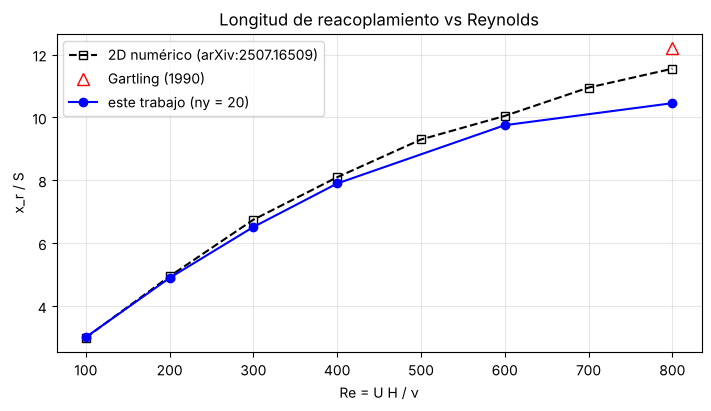

Re =  100   este trabajo =   3.01   referencia =   3.00   error =  +0.5 %
Re =  200   este trabajo =   4.90   referencia =   4.95   error =  -1.0 %
Re =  300   este trabajo =   6.52   referencia =   6.75   error =  -3.4 %
Re =  400   este trabajo =   7.90   referencia =   8.10   error =  -2.5 %
Re =  600   este trabajo =   9.75   referencia =  10.05   error =  -2.9 %
Re =  800   este trabajo =  10.45   referencia =  11.55   error =  -9.5 %


In [17]:
LIT_RE = np.array([100, 200, 300, 400, 500, 600, 700, 800])
LIT_XR = np.array([3.00, 4.95, 6.75, 8.10, 9.30, 10.05, 10.95, 11.55])   # x_r/S, arXiv:2507.16509 (Tabla 1)

runs_val = list(runs_re)
if RUN_RE800:
    r800 = solve_bfs(Re=800, ny=20, L=30.0, gamma=GAMMA, t_end=700, tol=1e-4)
    runs_val.append(r800)
    print(f"Re = 800: x_r/S = {r800['xr']/S:.2f} (Gartling 12.2);  burbuja superior "
          f"{r800['xs']:.2f}H – {r800['xe']:.2f}H (Gartling 4.85H – 10.48H)")

re_sim = np.array([r["Re"] for r in runs_val]); xr_sim = np.array([r["xr"] / S for r in runs_val])
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.plot(LIT_RE, LIT_XR, "ks--", mfc="none", label="2D numérico (arXiv:2507.16509)")
ax.plot([800], [12.2], "r^", ms=9, mfc="none", label="Gartling (1990)")
ax.plot(re_sim, xr_sim, "bo-", label="este trabajo (ny = 20)")
ax.set_xlabel("Re = U H / ν"); ax.set_ylabel("x_r / S"); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Longitud de reacoplamiento vs Reynolds")
fig.savefig(FIG / "validacion.png", dpi=150); plt.show()

for Re_, x in zip(re_sim, xr_sim):
    ref = np.interp(Re_, LIT_RE, LIT_XR)
    print(f"Re = {Re_:4d}   este trabajo = {x:6.2f}   referencia = {ref:6.2f}   error = {100*(x-ref)/ref:+5.1f} %")

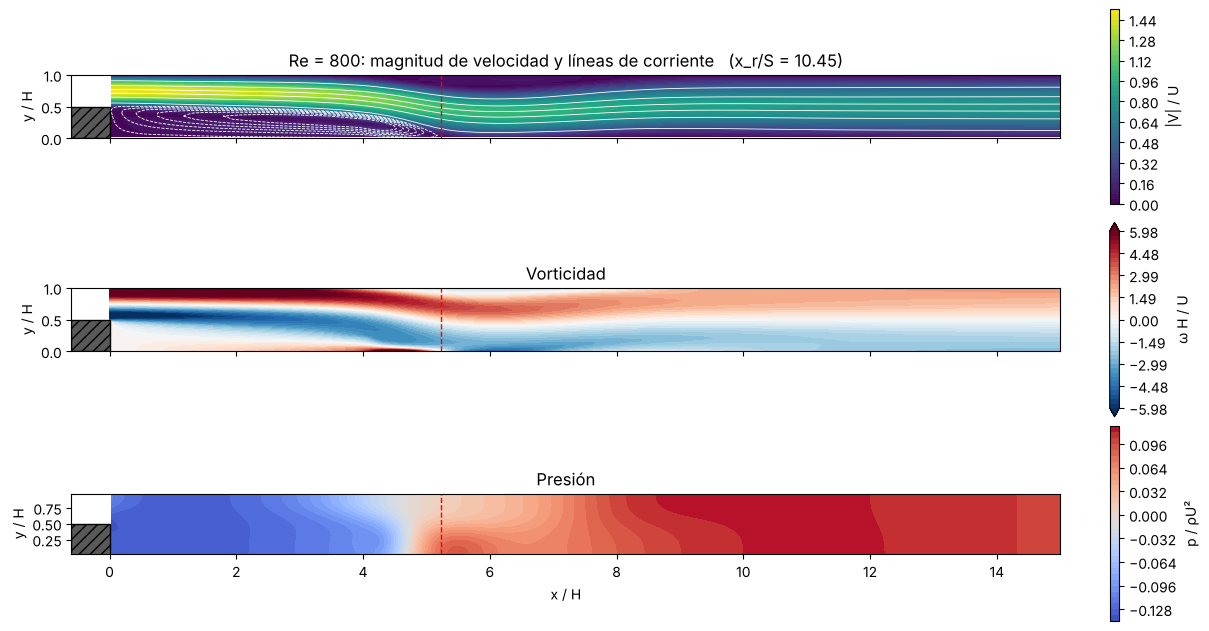

In [18]:
if RUN_RE800:
    plot_fields(r800, xmax=15, fname=FIG / "campos_re800.png"); plt.show()

**Discusión de la validación.** Con 20 celdas por $H$ la tendencia $x_r(Re)$ coincide con la tabla de referencia
dentro de ~3 % hasta Re = 600 y se reproduce la burbuja secundaria superior (incipiente en Re = 400, clara en Re ≥ 600).
Hay que leer esa coincidencia con cuidado: el estudio de malla (6.2) indica que el valor convergido a Re = 200 es
$x_r/S\approx 5.3$, y el esquema centrado ($\gamma=0$, 6.4) da lo mismo (5.33). Es decir, a 20 celdas/$H$ la difusión numérica
acorta la burbuja ~8 %, y parte del buen acuerdo con la tabla es cancelación de errores (la tabla además puede usar un canal
de entrada aguas arriba, que cambia el perfil en la arista). En Re = 800, con la misma configuración que Gartling (entrada en
el plano del escalón), la malla gruesa da 10.45 frente a 12.2: el error crece con $Re$ porque la capa de corte es más delgada
y $\nu_{num}/\nu$ aumenta. Para cerrar esa diferencia hace falta refinar (ny ≥ 40) o un esquema de mayor orden.

## 8. Conclusiones
* El solver de proyección en malla MAC conserva la masa a precisión de máquina y reproduce la física del escalón:
  separación en la arista, burbuja principal, reacoplamiento y, desde Re ≈ 400, burbuja secundaria en la pared superior.
* $x_r/S$ crece casi linealmente con $Re$ (menor viscosidad → la capa de corte tarda más en difundir momento hacia la pared)
  y sigue la tendencia de la literatura 2D (±3 % hasta Re = 600 con 20 celdas/H); en Re = 800 la malla gruesa subestima
  $x_r$ (10.45 vs 12.2 de Gartling) por difusión numérica.
* El estudio de malla muestra convergencia monótona con orden observado ~1 (por la parte upwind del esquema); con
  20 celdas por $H$ el error de discretización en $x_r$ es de algunos por ciento y crece con $Re$, lo que explica que en
  Re = 800 la burbuja quede más corta que la de Gartling.
* $\Delta t$ no cambia el estado estacionario mientras se respete el criterio CFL; por encima de él la integración explícita diverge.
* El upwind ($\gamma=1$) añade difusión numérica que acorta la burbuja; esto ilustra por qué en CFD importa el orden del esquema.

**Referencias**
1. Armaly, B. F., Durst, F., Pereira, J. C. F., Schönung, B. (1983). *Experimental and theoretical investigation of backward-facing step flow*. J. Fluid Mech. 127, 473–496.
2. Gartling, D. K. (1990). *A test problem for outflow boundary conditions — flow over a backward-facing step*. Int. J. Numer. Methods Fluids 11, 953–967.
3. Chorin, A. J. (1968). *Numerical solution of the Navier–Stokes equations*. Math. Comp. 22, 745–762.
4. Griebel, M., Dornseifer, T., Neunhoeffer, T. (1998). *Numerical Simulation in Fluid Dynamics: A Practical Introduction*. SIAM.
5. Roache, P. J. (1994). *Perspective: a method for uniform reporting of grid refinement studies*. J. Fluids Eng. 116, 405–413.
6. arXiv:2507.16509 (2025). *A Finite Volume and Levenberg–Marquardt Optimization Framework for Benchmarking MHD Flows over Backward-Facing Steps* (Tabla 1, caso hidrodinámico).
7. kangluosee, *CFD-Python: Combined backward facing step* (GitHub), código de referencia.